# Spectroscopy: CCD Characterisation and master bias/flat

`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 23 Oct 2023

Reference: *Handbook of CCD Astronomy*, §4.3
* compute CCD gain and readout noise
* compare with specifications
* compute master bias
* compute master flat

In [1]:
# import and settings
%matplotlib notebook
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.stats import mad_std
from astropy import units as u
from astropy.visualization import ZScaleInterval
import ccdproc as ccdp

In [2]:
# define CCD properties
ccd_gain = 0.37 # e-/ADU
ccd_ron = 6.0 # e-

In [4]:
# create calibration image collections
ifc_bias = ccdp.ImageFileCollection('calib/', glob_include='Bias_*.fit*')
print(ifc_bias.summary['file', 'date-obs', 'objname', 'exptime'], '\n')

ifc_flat = ccdp.ImageFileCollection('calib/', glob_include='Flat_*.fit*')
print(ifc_flat.summary['file', 'date-obs', 'objname', 'exptime'])

ifc_flat = ifc_flat.filter(objname='Soleil')
print(ifc_flat.summary['file', 'date-obs', 'objname', 'exptime'])

             file                   date-obs      objname exptime
----------------------------- ------------------- ------- -------
Bias_0s_20190613_001231-1.fit 2019-06-12T22:12:31    Lune       0
Bias_0s_20190613_001231-2.fit 2019-06-12T22:12:32    Lune       0
Bias_0s_20190613_001231-3.fit 2019-06-12T22:12:33    Lune       0
Bias_0s_20190613_001231-4.fit 2019-06-12T22:12:33    Lune       0
Bias_0s_20190613_001231-5.fit 2019-06-12T22:12:34    Lune       0 

             file                    date-obs      objname exptime
------------------------------ ------------------- ------- -------
 Flat_8s_20190611_194505-1.fit 2019-06-11T17:45:05  Soleil       8
Flat_8s_20190611_194505-10.fit 2019-06-11T17:46:23  Soleil       8
 Flat_8s_20190611_194505-2.fit 2019-06-11T17:45:14  Soleil       8
 Flat_8s_20190611_194505-3.fit 2019-06-11T17:45:23  Soleil       8
 Flat_8s_20190611_194505-4.fit 2019-06-11T17:45:31  Soleil       8
 Flat_8s_20190611_194505-5.fit 2019-06-11T17:45:40  Soleil       8


## CCD gain and readout noise

In [5]:
### Further work: compute CCD gain and RON from bias and flat-field frames
###   and compare w/ camera specifications: 
###   https://moodle.umontpellier.fr/mod/wiki/view.php?pageid=2792

Set MJD-END to 58645.739734 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.739734 from DATE-END'.


calib/Flat_8s_20190611_194505-1.fit


<IPython.core.display.Javascript object>


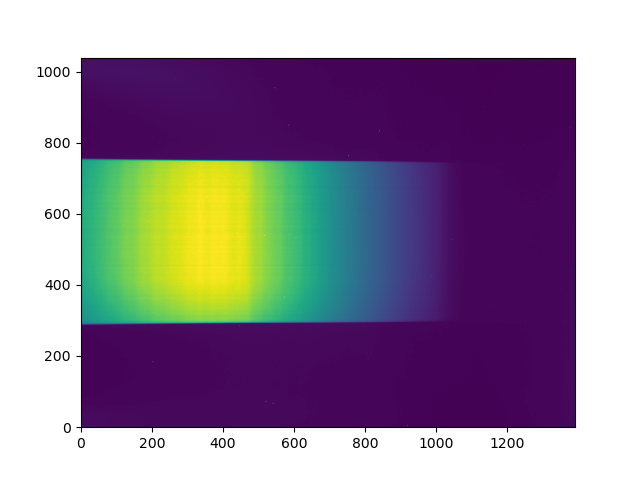

In [6]:
### Remark: Plot flat-field frames to identify illuminated area and compute stats only on that region
fnamel_flat = ifc_flat.files
print(fnamel_flat[0])
ccd_flat1 = ccdp.CCDData.read(fnamel_flat[0], unit='adu')
#
plt.figure()
interval = ZScaleInterval()
z1, z2 = interval.get_limits(ccd_flat1)
plt.imshow(ccd_flat1.data, origin='lower', vmin=z1, vmax=z2)
#plt.imshow(ccd_flat1.data[295:750,0:800], origin='lower', vmin=z1, vmax=z2)
plt.show()

## Master bias

In [7]:
# compute master bias
master_bias = ccdp.combine(ifc_bias.files_filtered(include_path=True), unit='adu', combine='average', mem_limit=512.e6)

Set MJD-END to 58646.925359 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.925359 from DATE-END'.
Set MJD-END to 58646.925370 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.925370 from DATE-END'.
Set MJD-END to 58646.925382 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.925382 from DATE-END'.
Set MJD-END to 58646.925394 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58646.925394 from DATE-END'.


In [8]:
# set header keyword (will appear in the saved file)
master_bias.meta['COMBINED'] = True

In [9]:
### Further work: compare statiscal properties of the series, the master frame and a residual image (bias_1 - master_bias )

In [10]:
### Further work: Display 1st bias, master bias and residual

In [11]:
# save master bias
master_bias.write('reference/master_bias.fits', hdu_mask=None, hdu_uncertainty=None, overwrite=True)

## Master Flat

In [12]:
# compute master flat with scaling/normalisation
master_flat = ccdp.combine(ifc_flat.files_filtered(include_path=True), unit='adu', method='average', mem_limit=512.e6)

INFO:astropy:splitting each image into 2 chunks to limit memory usage to 512000000.0 bytes.
Set MJD-END to 58645.740637 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740637 from DATE-END'.
Set MJD-END to 58645.739838 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.739838 from DATE-END'.
Set MJD-END to 58645.739942 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.739942 from DATE-END'.
Set MJD-END to 58645.740035 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740035 from DATE-END'.
Set MJD-END to 58645.740139 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740139 from DATE-END'.
Set MJD-END to 58645.740243 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740243 from DATE-END'.
Set MJD-END to 58645.740336 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740336 from DATE-END'.
Set MJD-END to 58645.740440 from DATE-END'. [astropy.wcs.wcs]
Set MJD-END to 58645.740440 from DATE-END'.
Set MJD-END to 58645.740532 from DATE-END'. [astropy.wcs.wcs

INFO: splitting each image into 2 chunks to limit memory usage to 512000000.0 bytes. [ccdproc.combiner]


In [13]:
# set header keyword (will appear in the saved file)
master_flat.meta['COMBINED'] = True

In [14]:
# print statiscal properties of master frame
npix = master_flat.shape[0]*master_flat.shape[1]
print('npix    mean    median  std  ')
print('-----------------------------')
print("%7d %5.2f   %5.2f  %5.2f" % (npix, np.mean(master_flat.data), np.median(master_flat.data), np.std(master_flat.data)))

npix    mean    median  std  
-----------------------------
1447680 7868.78   1912.40  10141.71


In [15]:
### Further work: compare statiscal properties of the series, the master frame and a residual image (bias_1 - master_bias )

In [16]:
### Further work: Display 1st bias, master bias and residual

In [17]:
# subtract master bias from master flat
master_flat_b = ccdp.subtract_bias(master_flat, master_bias)

In [18]:
# save master flat
master_flat_b.write('reference/master_flat.fits', overwrite=True)